# House Prices: CNN

## 1. Loading and preparing the dataset

In [9]:
import os
import time
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import gzip

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

In [10]:
DATA_DIR = "data"
FMNIST_BASE_URL = "http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/"
FMNIST_FILES = {
    "images": "train-images-idx3-ubyte.gz",
    "labels": "train-labels-idx1-ubyte.gz",
}
FMNIST_CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
                  'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
N_PER_CLASS = 2000


def _download(fname):
    os.makedirs(DATA_DIR, exist_ok=True)
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        with urllib.request.urlopen(FMNIST_BASE_URL + fname, timeout=20) as r, open(path, 'wb') as f:
            f.write(r.read())
    return path


def load_fashion_mnist():
    img_path = _download(FMNIST_FILES["images"])
    lbl_path = _download(FMNIST_FILES["labels"])
    with gzip.open(img_path, 'rb') as f:
        X = np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 28, 28)
    with gzip.open(lbl_path, 'rb') as f:
        y = np.frombuffer(f.read(), np.uint8, offset=8)
    rng = np.random.RandomState(SEED)
    keep = np.concatenate([rng.permutation(np.where(y == c)[0])[:N_PER_CLASS] for c in range(10)])
    keep = rng.permutation(keep)
    return X[keep].astype(np.float32) / 255.0, y[keep].astype(np.int64), FMNIST_CLASSES


loaded = load_fashion_mnist()
DATASET_NAME = "Fashion-MNIST"


X_all, y_all, CLASS_NAMES = loaded
N_CLASSES = len(CLASS_NAMES)

print(f"Dataset: {DATASET_NAME}")
print(f"Images: {len(X_all)}, size of each: {X_all.shape[1]}x{X_all.shape[2]}, classes: {N_CLASSES}")


Dataset: Fashion-MNIST
Images: 20000, size of each: 28x28, classes: 10


## 2. Exploratory data analysis

Shape of image array: (20000, 28, 28)  (N, height, width)
Pixel type: float32, range: [0.00, 1.00]
Pixel mean / std: 0.286 / 0.353
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

Class distribution:


,count
T-shirt/top,2000
Trouser,2000
Pullover,2000
Dress,2000
Coat,2000
Sandal,2000
Shirt,2000
Sneaker,2000
Bag,2000
Ankle boot,2000


Ratio of the largest class to the smallest: 1.00


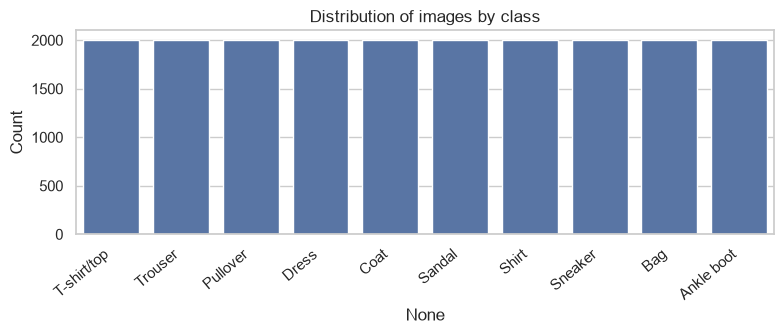

In [11]:
print(f"Shape of image array: {X_all.shape}  (N, height, width)")
print(f"Pixel type: {X_all.dtype}, range: [{X_all.min():.2f}, {X_all.max():.2f}]")
print(f"Pixel mean / std: {X_all.mean():.3f} / {X_all.std():.3f}")
print(f"Classes: {CLASS_NAMES}")

class_counts = pd.Series(y_all).value_counts().sort_index()
class_counts.index = [CLASS_NAMES[i] for i in class_counts.index]
print("\nClass distribution:")
display(class_counts.to_frame('count'))

imbalance = class_counts.max() / class_counts.min()
print(f"Ratio of the largest class to the smallest: {imbalance:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax)
ax.set_title('Distribution of images by class')
ax.set_ylabel('Count')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

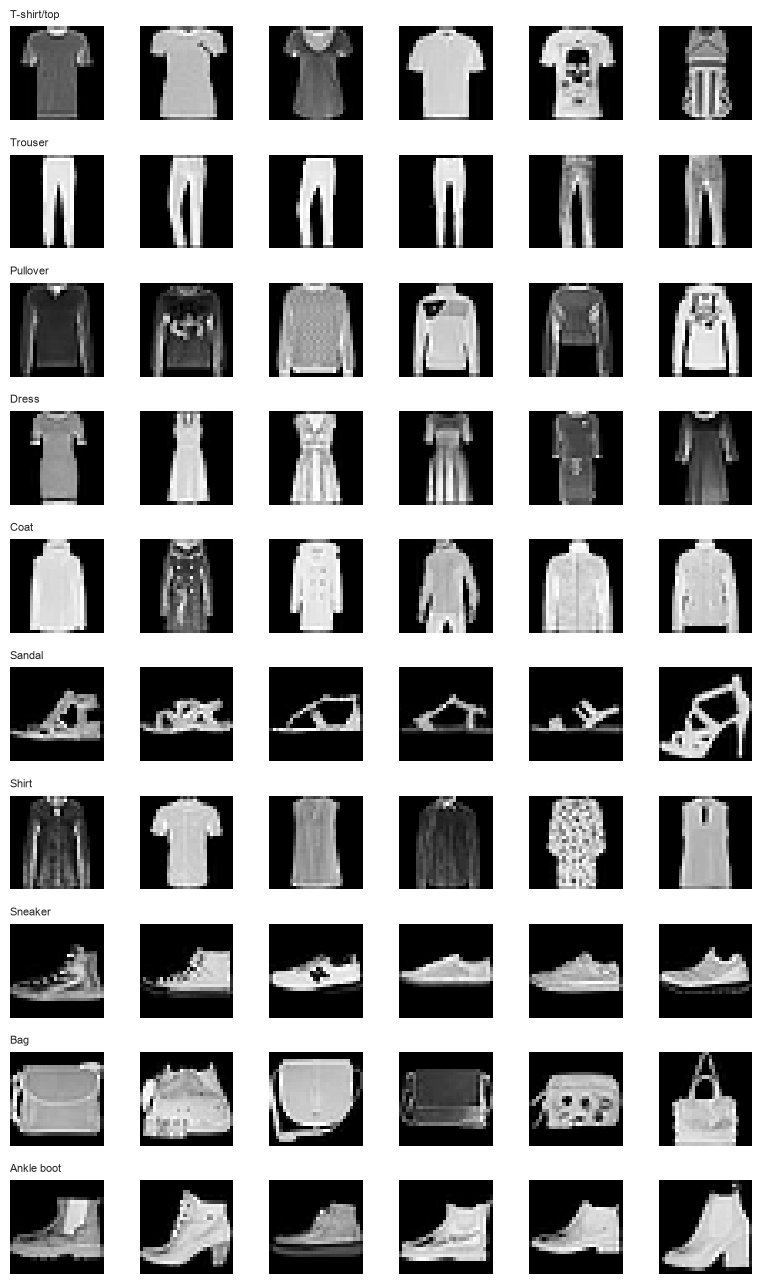

In [12]:
fig, axes = plt.subplots(N_CLASSES, 6, figsize=(8, 1.3 * N_CLASSES))
rng = np.random.RandomState(0)
for c in range(N_CLASSES):
    idx = rng.choice(np.where(y_all == c)[0], 6, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_all[i], cmap='gray')
        axes[c, j].axis('off')
    axes[c, 0].set_title(CLASS_NAMES[c], fontsize=8, loc='left')
plt.tight_layout()
plt.show()

## 3. Preparing data for training

In [13]:
IMG_SIZE = 28

X_t = torch.tensor(X_all).unsqueeze(1)
if X_t.shape[-1] != IMG_SIZE:
    X_t = F.interpolate(X_t, size=(IMG_SIZE, IMG_SIZE), mode='bilinear', align_corners=False)
y_t = torch.tensor(y_all)

print(f"Image tensor after resizing: {tuple(X_t.shape)}")

Image tensor after resizing: (20000, 1, 28, 28)


### 3.2 Splitting into train, validation, and test sets

In [15]:
idx_all = np.arange(len(y_t))
idx_trainval, idx_test = train_test_split(idx_all, test_size=0.15, random_state=SEED, stratify=y_all)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.15, random_state=SEED, stratify=y_all[idx_trainval])

X_train_raw, y_train = X_t[idx_train], y_t[idx_train]
X_val_raw, y_val = X_t[idx_val], y_t[idx_val]
X_test_raw, y_test = X_t[idx_test], y_t[idx_test]

print(f"train: {len(y_train)} | val: {len(y_val)} | test: {len(y_test)}")
split_share = pd.DataFrame({
    'train': pd.Series(y_train.numpy()).value_counts(normalize=True).sort_index(),
    'val': pd.Series(y_val.numpy()).value_counts(normalize=True).sort_index(),
    'test': pd.Series(y_test.numpy()).value_counts(normalize=True).sort_index(),
})
split_share.index = CLASS_NAMES
display(split_share)

train: 14450 | val: 2550 | test: 3000


,train,val,test
T-shirt/top,0.1,0.1,0.1
Trouser,0.1,0.1,0.1
Pullover,0.1,0.1,0.1
Dress,0.1,0.1,0.1
Coat,0.1,0.1,0.1
Sandal,0.1,0.1,0.1
Shirt,0.1,0.1,0.1
Sneaker,0.1,0.1,0.1
Bag,0.1,0.1,0.1
Ankle boot,0.1,0.1,0.1


### 3.3 Normalization

In [16]:
PIX_MEAN = X_train_raw.mean().item()
PIX_STD = X_train_raw.std().item()
print(f"Normalization parameters (train only): mean={PIX_MEAN:.4f}, std={PIX_STD:.4f}")

def normalize(x):
    return (x - PIX_MEAN) / PIX_STD

X_train, X_val, X_test = normalize(X_train_raw), normalize(X_val_raw), normalize(X_test_raw)
print(f"train: mean={X_train.mean():.3f}, std={X_train.std():.3f} | "
      f"val: mean={X_val.mean():.3f}, std={X_val.std():.3f} | "
      f"test: mean={X_test.mean():.3f}, std={X_test.std():.3f}")

Normalization parameters (train only): mean=0.2860, std=0.3529
train: mean=-0.000, std=1.000 | val: mean=0.007, std=1.003 | test: mean=-0.007, std=0.998


### 3.4 Augmentation

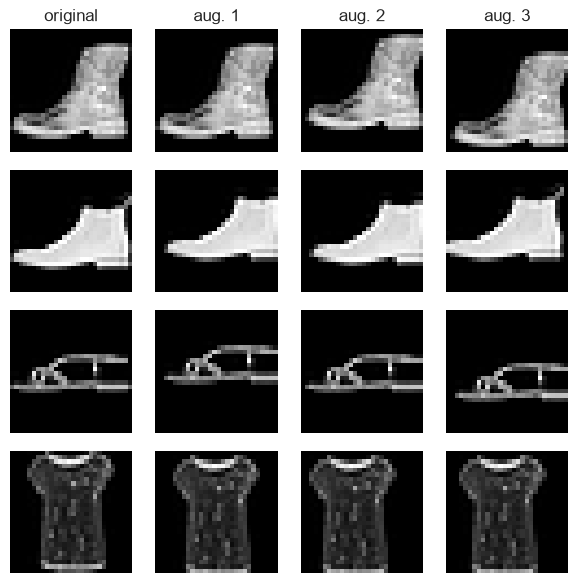

In [ ]:
def augment_batch(xb, max_shift=2):
    B, C, H, W = xb.shape
    bg = xb.amin().item()
    padded = F.pad(xb, (max_shift,) * 4, mode='constant', value=bg)
    dx = torch.randint(0, 2 * max_shift + 1, (B,))
    dy = torch.randint(0, 2 * max_shift + 1, (B,))
    return torch.stack([padded[i, :, dy[i]:dy[i] + H, dx[i]:dx[i] + W] for i in range(B)])


sample = X_train[:4]
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for r in range(4):
    axes[r, 0].imshow(sample[r, 0], cmap='gray')
    axes[r, 0].set_title('original' if r == 0 else '')
    for c in range(1, 4):
        axes[r, c].imshow(augment_batch(sample[r:r + 1])[0, 0], cmap='gray')
        if r == 0: 
            axes[r, c].set_title(f'aug. {c}')
for a in axes.ravel(): 
    a.axis('off')
plt.tight_layout()
plt.show()

## 4-5. CNN Architecture

## 5. Base MLP architecture

In [12]:
class MLPRegressor(nn.Module):
    def __init__(self, input_dim, hidden_sizes=(128, 64), dropout_p=0.0, activation=nn.ReLU):
        super().__init__()
        layers = []
        prev_dim = input_dim
        for h in hidden_sizes:
            layers.append(nn.Linear(prev_dim, h))
            layers.append(activation())
            if dropout_p > 0:
                layers.append(nn.Dropout(dropout_p))
            prev_dim = h
        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)
            
model_demo = MLPRegressor(input_dim=n_features, hidden_sizes=(128, 64))
print(model_demo)
print(f"\nNumber of trainable parameters: {count_parameters(model_demo):,}")

MLPRegressor(
  (net): Sequential(
    (0): Linear(in_features=304, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)

Number of trainable parameters: 47,361


## 6. Loss function, optimizer, and training hyperparameters

In [13]:
LEARNING_RATE = 0.001
N_EPOCHS_BASE = 150

print(f"Loss function: MSELoss")
print(f"Optimizer: Adam")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs (base model): {N_EPOCHS_BASE}")

Loss function: MSELoss
Optimizer: Adam
Learning rate: 0.001
Batch size: 32
Epochs (base model): 150


## 7–8. Training the base MLP model (without regularization)

In [14]:
def train_model(model, train_loader, X_val_t, y_val_t, n_epochs, learning_rate=0.001,
                 weight_decay=0.0, early_stopping_patience=None, verbose=False):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

    history = {'train_loss': [], 'val_loss': []}
    best_val_loss = float('inf')
    best_state = None
    epochs_no_improve = 0
    stopped_epoch = n_epochs

    t0 = time.time()
    for epoch in range(n_epochs):
        model.train()
        running_loss = 0.0
        n_batches = 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            pred = model(xb)
            loss = criterion(pred, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            n_batches += 1
        train_loss = running_loss / n_batches

        model.eval()
        with torch.no_grad():
            val_pred = model(X_val_t)
            val_loss = criterion(val_pred, y_val_t).item()

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if verbose and (epoch % 20 == 0 or epoch == n_epochs - 1):
            print(f"  Epoch {epoch+1}/{n_epochs}: train_loss={train_loss:.4f}, val_loss={val_loss:.4f}")
    
        if early_stopping_patience is not None and epochs_no_improve >= early_stopping_patience:
            stopped_epoch = epoch + 1
            if verbose:
                print(f"  Early stopping at epoch {stopped_epoch} (val_loss did not improve for {early_stopping_patience} consecutive epochs)")
            break

    train_time = time.time() - t0
    
    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, {'train_time': train_time, 'best_val_loss': best_val_loss, 'n_epochs_trained': stopped_epoch}

In [15]:
torch.manual_seed(RANDOM_STATE)
model_base = MLPRegressor(input_dim=n_features, hidden_sizes=(128, 64), dropout_p=0.0)

print("Training the base MLP model (without regularization)...")
model_base, history_base, info_base = train_model(
    model_base, train_loader, X_val_t, y_val_t,
    n_epochs=N_EPOCHS_BASE, learning_rate=LEARNING_RATE, weight_decay=0.0,
    early_stopping_patience=None, verbose=True
)

print(f"\nTraining time: {info_base['train_time']:.2f} s")
print(f"Best val_loss (MSE, scaled space): {info_base['best_val_loss']:.4f}")
print(f"Number of model parameters: {count_parameters(model_base):,}")

Training the base MLP model (without regularization)...
  Epoch 1/150: train_loss=0.4477, val_loss=0.1144
  Epoch 21/150: train_loss=0.0089, val_loss=0.0851
  Epoch 41/150: train_loss=0.0030, val_loss=0.0865
  Epoch 61/150: train_loss=0.0017, val_loss=0.0835
  Epoch 81/150: train_loss=0.0019, val_loss=0.0808
  Epoch 101/150: train_loss=0.0021, val_loss=0.0864
  Epoch 121/150: train_loss=0.0021, val_loss=0.0828
  Epoch 141/150: train_loss=0.0023, val_loss=0.0746
  Epoch 150/150: train_loss=0.0019, val_loss=0.0806

Training time: 28.80 s
Best val_loss (MSE, scaled space): 0.0642
Number of model parameters: 47,361


## 9. Plots of the base model training process

In [16]:
def regression_metrics(y_true_scaled, y_pred_scaled, scaler):
    y_true = scaler.inverse_transform(y_true_scaled.reshape(-1, 1)).ravel()
    y_pred = scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}


def predict_np(model, X_t):
    model.eval()
    with torch.no_grad():
        pred = model(X_t).cpu().numpy().ravel()
    return pred


def evaluate_model(model, X_t, y_scaled_arr, scaler):
    pred_scaled = predict_np(model, X_t)
    return regression_metrics(y_scaled_arr, pred_scaled, scaler)


base_train_metrics = evaluate_model(model_base, X_train_t, y_train_scaled, y_scaler)
base_val_metrics = evaluate_model(model_base, X_val_t, y_val_scaled, y_scaler)

print("Base MLP model metrics:")
pd.DataFrame({'train': base_train_metrics, 'validation': base_val_metrics}).T

Base MLP model metrics:


,MAE,MSE,RMSE,R2
train,11405.887869,3.829304e+08,19568.606652,0.944861
validation,14273.109161,4.457703e+08,21113.271940,0.927922


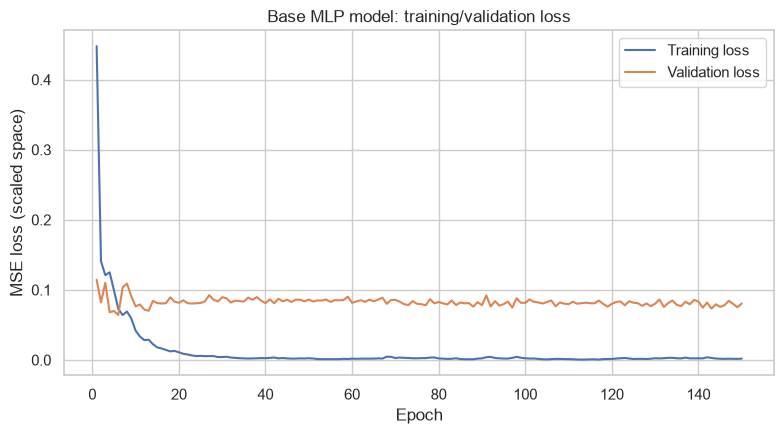

In [17]:
def plot_training_history(history, title, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 4.5))
    epochs_range = range(1, len(history['train_loss']) + 1)
    ax.plot(epochs_range, history['train_loss'], label='Training loss')
    ax.plot(epochs_range, history['val_loss'], label='Validation loss')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE loss (scaled space)')
    ax.set_title(title)
    ax.legend()
    return ax


plot_training_history(history_base, 'Base MLP model: training/validation loss')
plt.tight_layout()
plt.show()

## 10. Analysis of the training process

In [18]:
min_train_loss = min(history_base['train_loss'])
min_val_loss = min(history_base['val_loss'])
final_train_loss = history_base['train_loss'][-1]
final_val_loss = history_base['val_loss'][-1]
best_val_epoch = int(np.argmin(history_base['val_loss'])) + 1

print(f"Minimum training loss: {min_train_loss:.4f} (at the last epoch: {final_train_loss:.4f})")
print(f"Minimum validation loss: {min_val_loss:.4f} (reached at epoch {best_val_epoch} of {N_EPOCHS_BASE})")
print(f"Validation loss at the last epoch: {final_val_loss:.4f}")
print(f"\nR2 train: {base_train_metrics['R2']:.4f}, R2 validation: {base_val_metrics['R2']:.4f}")
print(f"R2 gap (train - val): {base_train_metrics['R2'] - base_val_metrics['R2']:.4f}")

Minimum training loss: 0.0005 (at the last epoch: 0.0019)
Minimum validation loss: 0.0642 (reached at epoch 6 of 150)
Validation loss at the last epoch: 0.0806

R2 train: 0.9449, R2 validation: 0.9279
R2 gap (train - val): 0.0169


## 11. Effect of network architecture

In [19]:
architectures = {
    'Small (1 layer, 32)':          {'hidden_sizes': (32,),        'activation': nn.ReLU},
    'Base (2 layers, 128-64)':      {'hidden_sizes': (128, 64),    'activation': nn.ReLU},
    'Deeper (3 layers, 128-64-32)': {'hidden_sizes': (128, 64, 32), 'activation': nn.ReLU},
    'Wide (2 layers, 256-128)':     {'hidden_sizes': (256, 128),   'activation': nn.ReLU},
    'Base, Tanh':                   {'hidden_sizes': (128, 64),    'activation': nn.Tanh},
}

architecture_results = []
architecture_models = {}
architecture_histories = {}

for name, cfg in architectures.items():
    torch.manual_seed(RANDOM_STATE)
    model = MLPRegressor(input_dim=n_features, hidden_sizes=cfg['hidden_sizes'],
                          dropout_p=0.0, activation=cfg['activation'])
    model, history, info = train_model(model, train_loader, X_val_t, y_val_t,
                                        n_epochs=N_EPOCHS_BASE, learning_rate=LEARNING_RATE,
                                        weight_decay=0.0, early_stopping_patience=None, verbose=False)
    val_metrics = evaluate_model(model, X_val_t, y_val_scaled, y_scaler)
    train_metrics = evaluate_model(model, X_train_t, y_train_scaled, y_scaler)

    architecture_models[name] = model
    architecture_histories[name] = history
    architecture_results.append({
        'architecture': name, 'n_params': count_parameters(model),
        'train_time_s': round(info['train_time'], 2),
        'best_val_loss': round(info['best_val_loss'], 4),
        'R2_train': round(train_metrics['R2'], 4), 'R2_val': round(val_metrics['R2'], 4),
        'RMSE_val': round(val_metrics['RMSE'], 1),
    })
    print(f"'{name}': done (n_params={count_parameters(model):,}, "
          f"val_loss={info['best_val_loss']:.4f}, time={info['train_time']:.1f}s)")

architecture_results_df = pd.DataFrame(architecture_results)
architecture_results_df

'Small (1 layer, 32)': done (n_params=9,793, val_loss=0.0732, time=11.7s)
'Base (2 layers, 128-64)': done (n_params=47,361, val_loss=0.0675, time=30.4s)
'Deeper (3 layers, 128-64-32)': done (n_params=49,409, val_loss=0.0686, time=31.5s)
'Wide (2 layers, 256-128)': done (n_params=111,105, val_loss=0.0690, time=35.7s)
'Base, Tanh': done (n_params=47,361, val_loss=0.0763, time=29.6s)


,architecture,n_params,train_time_s,best_val_loss,R2_train,R2_val,RMSE_val
0,"Small (1 layer, 32)",9793,11.65,0.0732,0.9339,0.9177,22554.5
1,"Base (2 layers, 128-64)",47361,30.39,0.0675,0.9269,0.9242,21652.5
2,"Deeper (3 layers, 128-64-32)",49409,31.52,0.0686,0.9170,0.9230,21825.3
3,"Wide (2 layers, 256-128)",111105,35.67,0.0690,0.9959,0.9225,21886.4
4,"Base, Tanh",47361,29.61,0.0763,0.9204,0.9143,23022.9


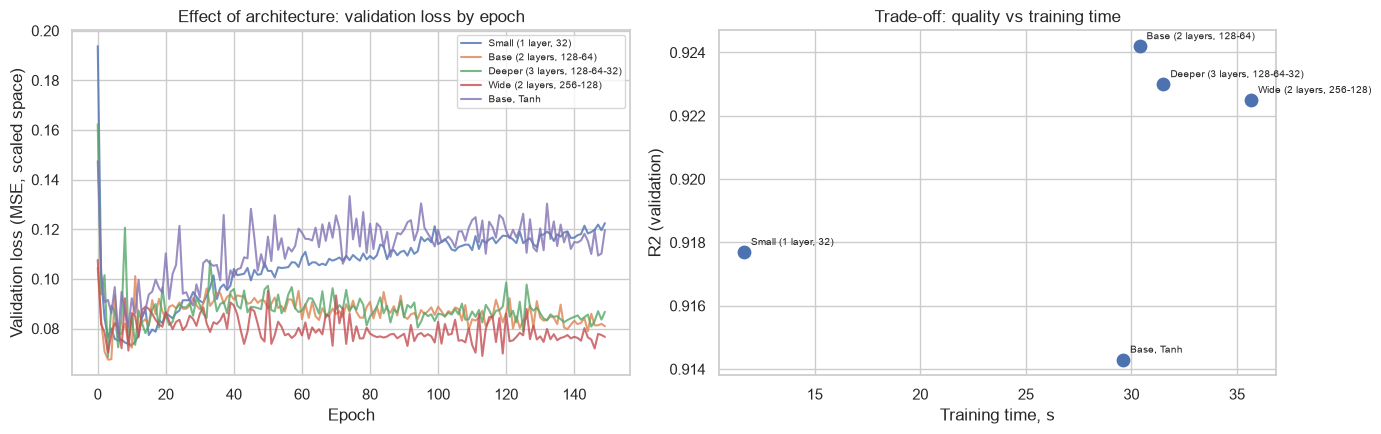

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for name, history in architecture_histories.items():
    axes[0].plot(history['val_loss'], label=name, alpha=0.8)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Validation loss (MSE, scaled space)')
axes[0].set_title('Effect of architecture: validation loss by epoch')
axes[0].legend(fontsize=7)

axes[1].scatter(architecture_results_df['train_time_s'], architecture_results_df['R2_val'], s=80)
for _, row in architecture_results_df.iterrows():
    axes[1].annotate(row['architecture'], (row['train_time_s'], row['R2_val']), fontsize=7,
                      xytext=(5, 5), textcoords='offset points')
axes[1].set_xlabel('Training time, s')
axes[1].set_ylabel('R2 (validation)')
axes[1].set_title('Trade-off: quality vs training time')

plt.tight_layout()
plt.show()

## 12–13. Regularization methods and comparison with the base model

In [21]:
regularization_configs = {
    'Dropout (p=0.3)':        {'dropout_p': 0.3, 'weight_decay': 0.0,  'early_stopping_patience': None},
    'L2 (weight_decay=1e-3)': {'dropout_p': 0.0, 'weight_decay': 1e-3, 'early_stopping_patience': None},
    'Early Stopping (patience=15)': {'dropout_p': 0.0, 'weight_decay': 0.0, 'early_stopping_patience': 15},
    'Combined (Dropout+L2+ES)':     {'dropout_p': 0.3, 'weight_decay': 1e-3, 'early_stopping_patience': 15},
}

reg_results = []
reg_models = {}
reg_histories = {}
reg_infos = {}

for name, cfg in regularization_configs.items():
    torch.manual_seed(RANDOM_STATE)
    model = MLPRegressor(input_dim=n_features, hidden_sizes=(128, 64), dropout_p=cfg['dropout_p'])
    model, history, info = train_model(
        model, train_loader, X_val_t, y_val_t, n_epochs=N_EPOCHS_BASE,
        learning_rate=LEARNING_RATE, weight_decay=cfg['weight_decay'],
        early_stopping_patience=cfg['early_stopping_patience'], verbose=False
    )
    val_metrics = evaluate_model(model, X_val_t, y_val_scaled, y_scaler)
    train_metrics = evaluate_model(model, X_train_t, y_train_scaled, y_scaler)

    reg_models[name] = model
    reg_histories[name] = history
    reg_infos[name] = info
    reg_results.append({
        'configuration': name, 'n_params': count_parameters(model),
        'n_epochs_trained': info['n_epochs_trained'],
        'train_time_s': round(info['train_time'], 2),
        'best_val_loss': round(info['best_val_loss'], 4),
        'R2_train': round(train_metrics['R2'], 4), 'R2_val': round(val_metrics['R2'], 4),
        'gap_R2': round(train_metrics['R2'] - val_metrics['R2'], 4),
    })
    print(f"'{name}': done (epochs={info['n_epochs_trained']}, val_loss={info['best_val_loss']:.4f})")

reg_results_df = pd.DataFrame(reg_results)
reg_results_df



'Dropout (p=0.3)': done (epochs=150, val_loss=0.0649)
'L2 (weight_decay=1e-3)': done (epochs=150, val_loss=0.0667)
'Early Stopping (patience=15)': done (epochs=20, val_loss=0.0646)
'Combined (Dropout+L2+ES)': done (epochs=28, val_loss=0.0668)


,configuration,n_params,n_epochs_trained,train_time_s,best_val_loss,R2_train,R2_val,gap_R2
0,Dropout (p=0.3),47361,150,30.74,0.0649,0.9905,0.9271,0.0634
1,L2 (weight_decay=1e-3),47361,150,41.82,0.0667,0.9407,0.9251,0.0156
2,Early Stopping (patience=15),47361,20,3.61,0.0646,0.9338,0.9275,0.0063
3,Combined (Dropout+L2+ES),47361,28,5.70,0.0668,0.9538,0.9250,0.0288


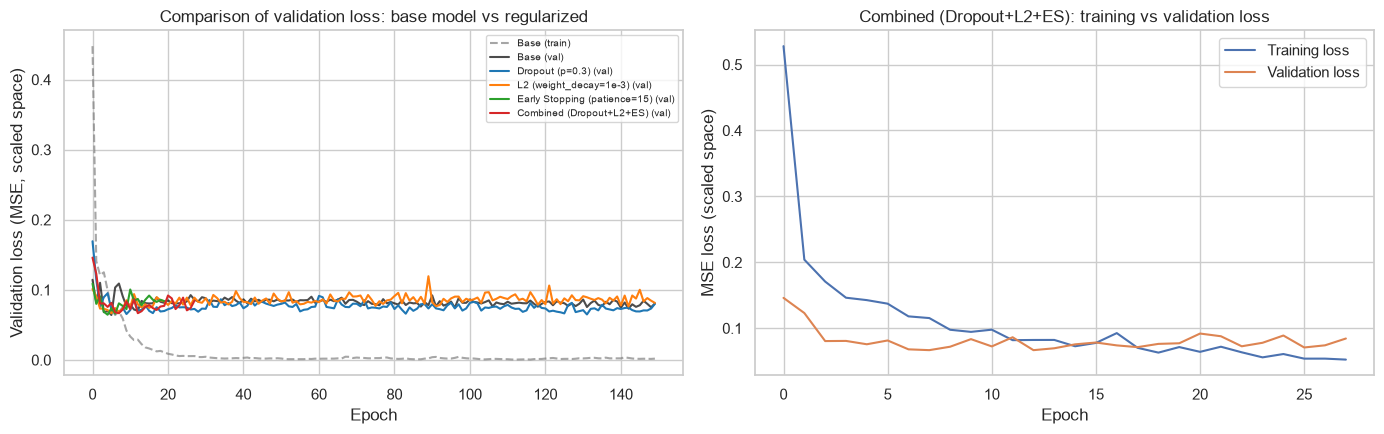

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(history_base['train_loss'], label='Base (train)', color='gray', linestyle='--', alpha=0.7)
axes[0].plot(history_base['val_loss'], label='Base (val)', color='black', alpha=0.7)
colors = plt.cm.tab10.colors
for i, (name, history) in enumerate(reg_histories.items()):
    axes[0].plot(history['val_loss'], label=f'{name} (val)', color=colors[i % 10])
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Validation loss (MSE, scaled space)')
axes[0].set_title('Comparison of validation loss: base model vs regularized')
axes[0].legend(fontsize=7)

combo_name = 'Combined (Dropout+L2+ES)'
axes[1].plot(reg_histories[combo_name]['train_loss'], label='Training loss')
axes[1].plot(reg_histories[combo_name]['val_loss'], label='Validation loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MSE loss (scaled space)')
axes[1].set_title(f'{combo_name}: training vs validation loss')
axes[1].legend()

plt.tight_layout()
plt.show()

## 14–15. Comparative table of the MLP configurations

In [23]:
best_arch_name = architecture_results_df.loc[
    architecture_results_df['architecture'] != 'Base (2 layers, 128-64)', 'R2_val'
].astype(float).idxmax()
best_arch_name = architecture_results_df.loc[best_arch_name, 'architecture']
best_arch_model = architecture_models[best_arch_name]

best_reg_name = reg_results_df['R2_val'].astype(float).idxmax()
best_reg_name = reg_results_df.loc[best_reg_name, 'configuration']
best_reg_model = reg_models[best_reg_name]

print(f"Best alternative architecture (by R2_val): {best_arch_name}")
print(f"Best configuration with regularization (by R2_val): {best_reg_name}")

Best alternative architecture (by R2_val): Deeper (3 layers, 128-64-32)
Best configuration with regularization (by R2_val): Early Stopping (patience=15)


In [24]:
def full_eval_row(model, name, n_epochs_trained, train_time, best_val_loss):
    val_m = evaluate_model(model, X_val_t, y_val_scaled, y_scaler)
    return {
        'Configuration': name,
        'Number of parameters': count_parameters(model),
        'Epochs trained': n_epochs_trained,
        'Best val_loss (MSE, scaled)': round(best_val_loss, 4),
        'MAE_val': round(val_m['MAE'], 1), 'RMSE_val': round(val_m['RMSE'], 1), 'R2_val': round(val_m['R2'], 4),
        'Training time, s': round(train_time, 2),
    }

final_comparison = pd.DataFrame([
    full_eval_row(model_base, 'Base MLP (128-64, without regularization)',
                   info_base['n_epochs_trained'], info_base['train_time'], info_base['best_val_loss']),
    full_eval_row(best_arch_model, f'MLP with modified architecture ({best_arch_name})',
                   N_EPOCHS_BASE, architecture_results_df.set_index('architecture').loc[best_arch_name, 'train_time_s'],
                   architecture_results_df.set_index('architecture').loc[best_arch_name, 'best_val_loss']),
    full_eval_row(best_reg_model, f'MLP with regularization ({best_reg_name})',
                   reg_infos[best_reg_name]['n_epochs_trained'], reg_infos[best_reg_name]['train_time'],
                   reg_infos[best_reg_name]['best_val_loss']),
]).set_index('Configuration')

final_comparison

,Number of parameters,Epochs trained,"Best val_loss (MSE, scaled)",MAE_val,RMSE_val,R2_val,"Training time, s"
Configuration,,,,,,,
"Base MLP (128-64, without regularization)",47361,150,0.0642,14273.1,21113.3,0.9279,28.80
"MLP with modified architecture (Deeper (3 layers, 128-64-32))",49409,150,0.0686,15040.9,21825.3,0.9230,31.52
MLP with regularization (Early Stopping (patience=15)),47361,20,0.0646,14265.4,21176.1,0.9275,3.61


## 16. Selecting the most suitable MLP configuration

In [25]:
final_models = {
    'Base MLP': model_base,
    f'Architecture: {best_arch_name}': best_arch_model,
    f'Regularization: {best_reg_name}': best_reg_model,
}

best_config_name = final_comparison['R2_val'].idxmax()
print(f"By the criterion of the highest R2_val, selected: {best_config_name}")

name_to_model = {
    'Base MLP (128-64, without regularization)': model_base,
    f'MLP with modified architecture ({best_arch_name})': best_arch_model,
    f'MLP with regularization ({best_reg_name})': best_reg_model,
}
final_model = name_to_model[best_config_name]

By the criterion of the highest R2_val, selected: Base MLP (128-64, without regularization)


## 17. Final evaluation of the selected configuration

In [26]:
X_trainval_raw = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

prep_final = build_preprocessor(X_trainval_raw)
X_trainval_final = apply_preprocessor(X_trainval_raw, prep_final).reset_index(drop=True)
X_test_final_2 = apply_preprocessor(X_test, prep_final).reset_index(drop=True)

y_scaler_final = StandardScaler()
y_trainval_scaled = y_scaler_final.fit_transform(y_trainval.values.reshape(-1, 1)).ravel()
y_test_scaled_2 = y_scaler_final.transform(y_test.values.reshape(-1, 1)).ravel()

X_trainval_t2, y_trainval_t2 = to_tensor(X_trainval_final, y_trainval_scaled)
X_test_t2, y_test_t2 = to_tensor(X_test_final_2, y_test_scaled_2)

trainval_dataset = TensorDataset(X_trainval_t2, y_trainval_t2)
trainval_loader = DataLoader(trainval_dataset, batch_size=BATCH_SIZE, shuffle=True,
                              generator=torch.Generator().manual_seed(RANDOM_STATE))

config_lookup = {
    'Base MLP (128-64, without regularization)': dict(hidden_sizes=(128, 64), dropout_p=0.0, weight_decay=0.0,
                                                      early_stopping_patience=None, n_epochs=N_EPOCHS_BASE),
    f'MLP with modified architecture ({best_arch_name})': dict(
        hidden_sizes=architectures[best_arch_name]['hidden_sizes'], dropout_p=0.0, weight_decay=0.0,
        early_stopping_patience=None, n_epochs=N_EPOCHS_BASE),
    f'MLP with regularization ({best_reg_name})': dict(
        hidden_sizes=(128, 64), dropout_p=regularization_configs[best_reg_name]['dropout_p'],
        weight_decay=regularization_configs[best_reg_name]['weight_decay'],
        early_stopping_patience=regularization_configs[best_reg_name]['early_stopping_patience'],
        n_epochs=N_EPOCHS_BASE),
}
chosen_cfg = config_lookup[best_config_name]


n_features_final = X_trainval_final.shape[1]
print(f"Input layer dimensionality for retraining on train+val: {n_features_final} ")


torch.manual_seed(RANDOM_STATE)
final_model_retrained = MLPRegressor(input_dim=n_features_final, hidden_sizes=chosen_cfg['hidden_sizes'],
                                      dropout_p=chosen_cfg['dropout_p'])

final_model_retrained, history_final, info_final = train_model(
    final_model_retrained, trainval_loader, X_test_t2, y_test_t2,
    n_epochs=chosen_cfg['n_epochs'], learning_rate=LEARNING_RATE,
    weight_decay=chosen_cfg['weight_decay'],
    early_stopping_patience=chosen_cfg['early_stopping_patience'], verbose=False
)

print(f"Final model ({best_config_name}) retrained on train+val "
      f"({X_trainval_final.shape[0]} objects), {info_final['n_epochs_trained']} epochs.")

Input layer dimensionality for retraining on train+val: 312 
Final model (Base MLP (128-64, without regularization)) retrained on train+val (1168 objects), 150 epochs.


In [27]:
final_test_metrics = evaluate_model(final_model_retrained, X_test_t2, y_test_scaled_2, y_scaler_final)

print("Final metrics on the test sample:")
pd.Series(final_test_metrics).to_frame('test')

Final metrics on the test sample:


,test
MAE,1.463982e+04
MSE,7.760540e+08
RMSE,2.785775e+04
R2,8.266471e-01


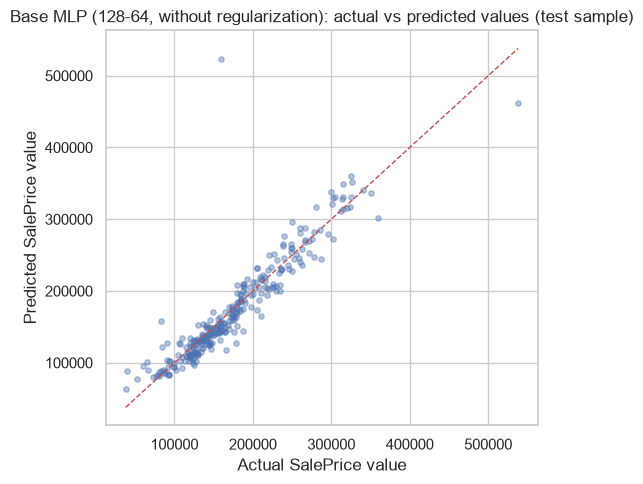

In [28]:
y_test_pred = y_scaler_final.inverse_transform(
    predict_np(final_model_retrained, X_test_t2).reshape(-1, 1)
).ravel()

plt.figure(figsize=(5.5, 5))
plt.scatter(y_test.values, y_test_pred, alpha=0.4, s=15)
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
plt.plot(lims, lims, 'r--', linewidth=1)
plt.xlabel('Actual SalePrice value')
plt.ylabel('Predicted SalePrice value')
plt.title(f'{best_config_name}: actual vs predicted values (test sample)')
plt.tight_layout()
plt.show()

## 18. Final justification of the selected MLP configuration

In [29]:
print("Comparison of the three studied configurations on validation:")
display(final_comparison)

print(f"\nSelected configuration: {best_config_name}")
display(pd.Series(final_test_metrics).to_frame('test'))

Comparison of the three studied configurations on validation:


,Number of parameters,Epochs trained,"Best val_loss (MSE, scaled)",MAE_val,RMSE_val,R2_val,"Training time, s"
Configuration,,,,,,,
"Base MLP (128-64, without regularization)",47361,150,0.0642,14273.1,21113.3,0.9279,28.80
"MLP with modified architecture (Deeper (3 layers, 128-64-32))",49409,150,0.0686,15040.9,21825.3,0.9230,31.52
MLP with regularization (Early Stopping (patience=15)),47361,20,0.0646,14265.4,21176.1,0.9275,3.61



Selected configuration: Base MLP (128-64, without regularization)


,test
MAE,1.463982e+04
MSE,7.760540e+08
RMSE,2.785775e+04
R2,8.266471e-01
